Visualizing ODEs

In this workshop, we'll talk about visualizing ordinary differential equations.

**Topics covered here**

- Numerically solving a simple 1D ODE
    - Phase portraits
    - Fixed points - attractive and repulsive
- Damped particle motion in 2D
    - Phase portrait
    - Trajectories through phase space

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Part 1: Visualizing a simple 1D ODE

We'll start with visualizing a very simple one dimensional ODE.

$\frac{dx}{dt} = - x (x - 1)(x+2)$

### 1.1: Phase spaces and portraits.

The first thing we can look at here is the system's **phase portrait**. The system has a **phase space**, given by the possible states of the variable or variables composing it. Here, we just have one variable, x. The phase portrait tells is where the system will go next if it has a certain position in phase space. This is given by just plotting $\frac{dx}{dt}$ with respect to $x$. 

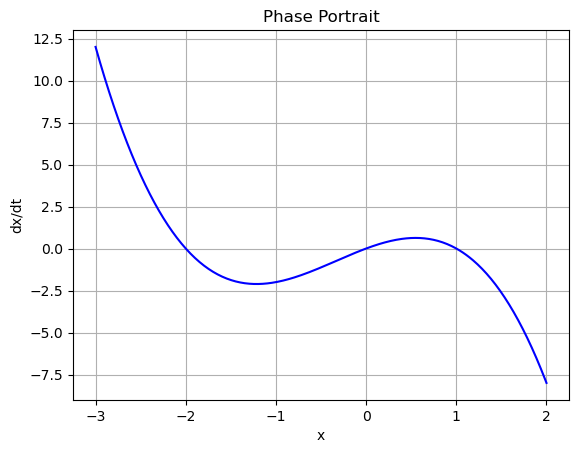

In [2]:
def dxdt(x):
    return -x * (x - 1) * (x + 2)

x_vals = np.linspace(-3, 2, 400) # phase space to plot
dxdt_vals = dxdt(x_vals) # dxdt at each point

plt.plot(x_vals, dxdt_vals, 'b')
plt.title("Phase Portrait")
plt.xlabel("x")
plt.ylabel("dx/dt")
plt.grid(True)
plt.show()

### 1.2: Fixed points

The **fixed points** of a differential equation are points where the system will be stationary. They're defined by 

$a$ is a fixed point if $\frac{dx}{dt}\big|_a = 0$ 

There are multiple types of fixed points - in this example we see three. There are **Attractive** and **Repulsive** fixed points. Since the slope of $\frac{dx}{dt}$ is negative at $x$ = -2 and $x$ = +1, these will be attractive fixed points, since $\frac{dx}{dt}$ above -2 (and +1) s negative and below -2 (and +1) so if we are a small distance from -2 or +1, the system will be drive towards -2 and +1. $x = 0$ is a repulsive fixed point, since $\frac{dx}{dt}$ is positive above 0 and negative below 0, meaning the system will be driven away.

For a higher dimensional system, there are also **saddle** fixed points, where if you perturb one system variable it's repulsive, while if you perturb another its attractive.

### 1.3: Checking fixed points

To confirm that the fixed points are what we think they are, we can solve the diffeq using Euler's method.

$x_{n+1} = x_n + v_n \cdot dt = x_n - x_n (x_n - 1)(x_n+2) \cdot dt$

From this we'll see that the system is pulled into the attractive fixed points at -2 and 1, and repelled by the point at 0. However, if the system is right at 0, it will stay there since $\frac{dx}{dt}$ = 0.

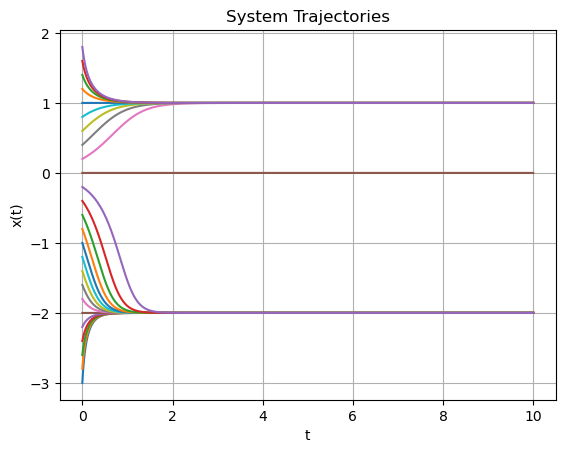

In [3]:
# Euler's method
dt = 0.001           # time step
T = 10.0             # total simulation time
N = int(T / dt)      # number of steps
t = np.linspace(0, T, N) # times
x = np.zeros(N) #positions

# let's try Euler's method for a few initial conditions
initial_conditions = np.arange(-3, 2, 0.2)

for x0 in initial_conditions:
    x[0] = x0
    for n in range(N-1):
        x[n+1] = x[n] + dxdt(x[n]) * dt # update position 
    plt.plot(t, x)

plt.title("System Trajectories")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.grid(True)
plt.show()

## Part 2: Visualizing a 2D ODE

For a 2D example, let's look back at one we've seen before, where a particle moves back and forth in a quartic trap. Here,

$V(x) = k\,x^4$, with a drag coefficent of $\gamma$

The differential equation describing this is

$\frac{d^2x}{dt^2} = -\frac{4k}{m} x^3 - \frac{\gamma}{m} \frac{dx}{dt}$

### 2.1: 2D Phase portrait

This second order ODE can be written as two coupled first order ODEs. This is how we solved it in Workshop 6!

$\frac{dx}{dt} = v$, and

$\frac{dv}{dt} = -\frac{dV}{dx} - \frac{\gamma}{m}  v = -\frac{4k}{m} x^3 - \frac{\gamma}{m}  v$

Since we have two variables defining our system, the phase space is now two dimensional. This means or phase portrait will also be two dimensional. Above, since we just had one variable, the function defining where our system went next was just one variable. However, since we now have two variables, we have to use a **vector field** to describe the direction in which the system will move next. Thankfully python has a way for us to plot this!

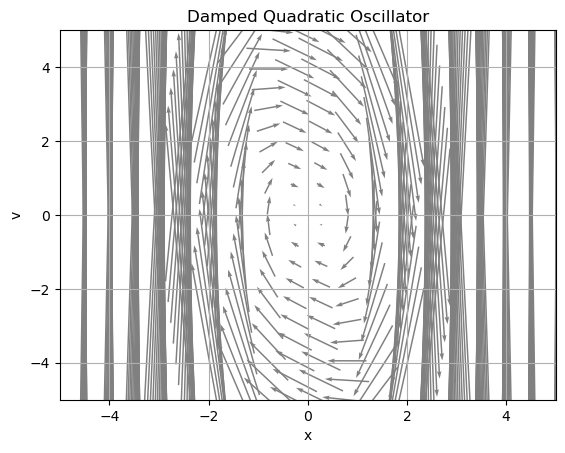

In [4]:
# Parameters
k = 1
m = 1
gamma = 0.5

x_vals = np.linspace(-5, 5, 20) # 2D phase space
v_vals = np.linspace(-5, 5, 20)
X, V = np.meshgrid(x_vals, v_vals) # make a meshgrid

DXDT = V # Evaluate dxdt and dvdt at each point in the grid
DVDT = -4 * k / m * X**3 - gamma / m * V

# Plot the vector field using quiver
# scale sets the size of the vectors
# pivot sets the middle of the vector to the point where it's evaluated
plt.quiver(X, V, DXDT, DVDT, color='gray', pivot='mid', scale=50)
plt.title("Damped Quadratic Oscillator")
plt.xlabel("x")
plt.ylabel("v")
plt.grid(True)
plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

### 2.2: Finding trajectoreis

Like in Workshop 6, we can again use Euler's method to solve Newton's equations of motion with $f = -\frac{dV}{dx} - \gamma v = m a$, where $\frac{dx}{dt} = v$. From our initial position $x_0$ and initial velocity $v_0$, Euler's method tells us a method to find the next velocity and positon in the time series:

$x_{n+1} = x_n + v_n \cdot dt$

$v_{n+1} = v_n + \frac{a_n}{m}\,dt = v_n + \frac{-4 k x^3_n - \gamma v_n}{m}\,dt$

Let's solve for a few trajectories, and plot them on top of our phase portrait. We'll see that the state of the system follows where vector field shown by the phase portrait pushes it.

Previously we plotted $x$ vs time, but now let's plot in the phase space, $x$ vs $v$.

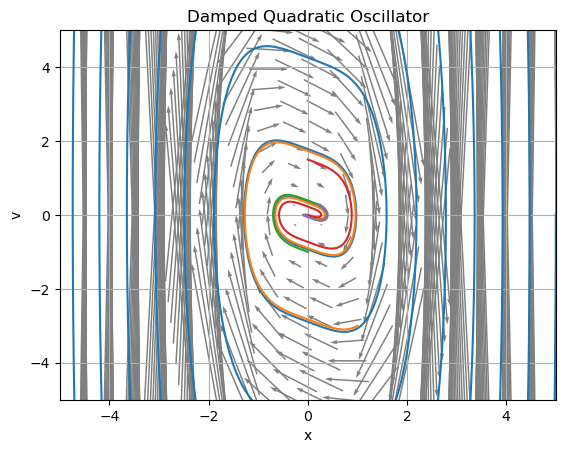

In [5]:
# Phase portrati
x_vals = np.linspace(-5, 5, 20) # 2D phase space
v_vals = np.linspace(-5, 5, 20)
X, V   = np.meshgrid(x_vals, v_vals) # make a meshgrid

DXDT = V # Evaluate dxdt and dvdt at each point in the grid
DVDT = -4 * k / m * X**3 - gamma / m * V

# Plot the vector field using quiver
# scale sets the size of the vectors
# pivot sets the middle of the vector to the point where it's evaluated
plt.quiver(X, V, DXDT, DVDT, color='gray', pivot='mid', scale=50)



# Euler's method
dt = 0.001           # time step
T = 100.0             # total simulation time
N = int(T / dt)      # number of steps
t = np.linspace(0, T, N) # times
x = np.zeros(N) #positions
v = np.zeros(N) #velocities

# let's try Euler's method for a few initial conditions
initial_conditions = [[5, 0], [1, -3], [0, -1], [0, 1.5], [0.2, 0.3]]

for init in initial_conditions:
    x[0] = init[0]
    v[0] = init[1]
    for n in range(N-1):
        a = (-4 * k * x[n]**3 - gamma * v[n]) / m  # acceleration
        v[n+1] = v[n] + a * dt                     # update velocity
        x[n+1] = x[n] + v[n] * dt                  # update position 
    plt.plot(x, v) # plot on phase space

plt.title("Damped Quadratic Oscillator")
plt.xlabel("x")
plt.ylabel("v")
plt.grid(True)
plt.xlim(-5,5)
plt.ylim(-5,5)
plt.show()

### 2.3: Attractive and repulsive fixed points

With the trajectories swirling in, we can see x = 0, v = 0 is an attractive fixed point for positive $\gamma$.

However, we can make it repulsive via a simple change! Making $\gamma$ negative! Of course this is non physical (it would mean the particle's velocity continually increases!), but it can help us illustrate what this looks like.

We can also explore how it looks for various values of $\gamma$ in between, including $\gamma$ = 0. If $\gamma$ = 0, energy is conserved, meaning the system won't spiral off or collapse to a fix point - it will simply orbit around (phase space trajectories are sometimes called orbits). Let's take a look at that looks like as well!

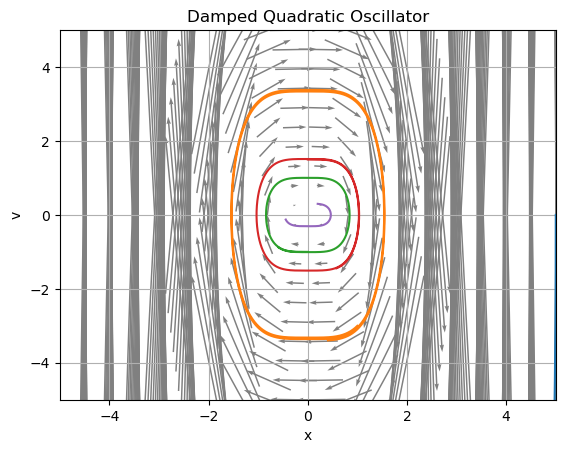

In [7]:
# Parameters
k = 1
m = 1
gamma = 0

# Phase portrati
x_vals = np.linspace(-5, 5, 20) # 2D phase space
v_vals = np.linspace(-5, 5, 20)
X, V = np.meshgrid(x_vals, v_vals) # make a meshgrid

DXDT = V # Evaluate dxdt and dvdt at each point in the grid
DVDT = -4 * k / m * X**3 - gamma / m * V

# Plot the vector field using quiver
# scale sets the size of the vectors
# pivot sets the middle of the vector to the point where it's evaluated
plt.quiver(X, V, DXDT, DVDT, color='gray', pivot='mid', scale=50)



# Euler's method
dt = 0.001           # time step
T = 5.0             # total simulation time
N = int(T / dt)      # number of steps
t = np.linspace(0, T, N) # times
x = np.zeros(N) #positions
v = np.zeros(N) #velocities

# let's try Euler's method for a few initial conditions
initial_conditions = [[5, 0], [1, -3], [0, -1], [0, 1.5], [0.2, 0.3]]

for init in initial_conditions:
    x[0] = init[0]
    v[0] = init[1]
    for n in range(N-1):
        a = (-4 * k * x[n]**3 - gamma * v[n]) / m  # acceleration
        v[n+1] = v[n] + a * dt                     # update velocity
        x[n+1] = x[n] + v[n] * dt                  # update position 
    plt.plot(x, v) # plot on phase space

plt.title("Damped Quadratic Oscillator")
plt.xlabel("x")
plt.ylabel("v")
plt.grid(True)
plt.xlim(-5,5)
plt.ylim(-5,5)
plt.show()